# A three-dimensional grounded cube

Solve a manufactured Poisson problem with OneSimulation, inspect a slice, and compare the complete field with an exact solution. The default output below was computed with 16 cells in each direction. Change the defaults in the first code cell and rerun.

The browser example evaluates the exact eigenmode of the standard nodal seven-point stencil. This notebook assembles and solves the full OneSimulation discretization; its cell-centre RMS error and the browser nodal maximum error use different sample locations and norms.

16³ cells; source amplitude 1 V; slice z=0.500 m
Cell-centre RMS error against the exact 3D solution: 1.138076e-03 V


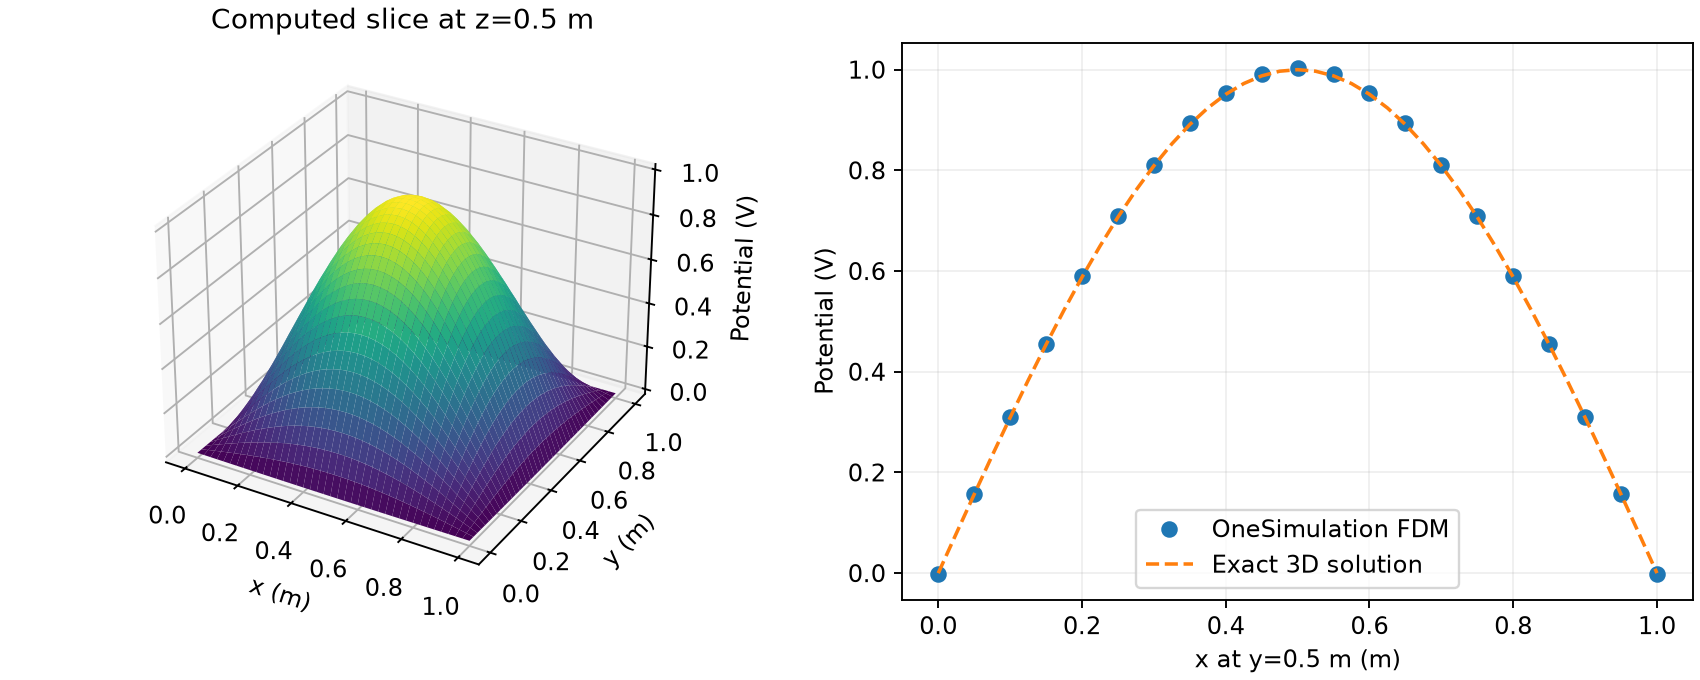

In [1]:
"""Solve a grounded three-dimensional cube with OneSimulation and verify the field."""
import argparse
from dataclasses import dataclass
import numpy as np
import matplotlib.pyplot as plt
from onesim.cad.d3 import Box
from onesim.meshing import StructuredHexahedralMesher
from onesim.numerics import Numerics
from onesim.numerics.linear import SparseDirect
from onesim.numerics.fdm import FiniteDifference, CentralDifference, CentralLaplacian
from onesim.physics.electrostatics import FixedPotential, PoissonEquation
from onesim.simulation import Problem, Simulation

parser = argparse.ArgumentParser(description=__doc__)
parser.add_argument('--cells', type=int, default=16)
parser.add_argument('--amplitude', type=float, default=1.0, help='Reference potential amplitude in V')
parser.add_argument('--slice', type=float, default=50, help='Depth as a percentage of the cube')
args = parser.parse_args([])  # Edit the defaults above or supply options here.
if not 8 <= args.cells <= 24 or not np.isfinite(args.amplitude) or args.amplitude <= 0 or not 0 <= args.slice <= 100:
    parser.error('Use 8–24 cells, a finite positive amplitude, and a slice between 0 and 100 percent')

@dataclass(frozen=True)
class Permittivity:
    unit = 'F/m'
    def evaluate(self, **state):
        return 1.0

cube = Box(length=1, width=1, height=1)
exact = lambda x, y, z: args.amplitude * np.sin(np.pi*x) * np.sin(np.pi*y) * np.sin(np.pi*z)
field = PoissonEquation(domain=cube.volume, permittivity=Permittivity(),
                        charge_density=lambda x, y, z: 3*np.pi**2*exact(x,y,z))
problem = Problem(name='Three-dimensional manufactured potential', geometry=cube, physics=(field,),
                  boundary_conditions=(FixedPotential(physics=field, boundary=cube.boundaries.all, value=0.0),))
mesh = StructuredHexahedralMesher(cells=(args.cells,)*3).generate(cube)
simulation = Simulation(problem=problem, mesh=mesh, numerics=Numerics(
    spatial=FiniteDifference(gradient=CentralDifference(), diffusion=CentralLaplacian()),
    linear_solver=SparseDirect()))
simulation.validate().require_valid()
result = simulation.solve_stationary()
potential = result.field(field.potential)
centres = mesh.coordinates[mesh.cells].mean(axis=1)
computed = potential.evaluate(centres)
reference = exact(*centres.T)
error = np.sqrt(np.mean((computed-reference)**2))
z = round(args.cells*args.slice/100)/args.cells
print(f'{args.cells}³ cells; source amplitude {args.amplitude:g} V; slice z={z:.3f} m')
print(f'Cell-centre RMS error against the exact 3D solution: {error:.6e} V')

x = np.linspace(0,1,41)
X,Y = np.meshgrid(x,x)
points = np.column_stack([X.ravel(),Y.ravel(),np.full(X.size,z)])
V = potential.evaluate(points).reshape(X.shape)
line = np.column_stack([x,np.full_like(x,.5),np.full_like(x,z)])
fig = plt.figure(figsize=(10,4),layout='constrained')
ax = fig.add_subplot(121,projection='3d')
surface = ax.plot_surface(X,Y,V,cmap='viridis',linewidth=0)
ax.set(xlabel='x (m)',ylabel='y (m)',zlabel='Potential (V)',title=f'Computed slice at z={z:g} m')
ax = fig.add_subplot(122)
ax.plot(x,potential.evaluate(line),'o',markevery=2,label='OneSimulation FDM')
ax.plot(x,exact(x,.5,z),'--',label='Exact 3D solution')
ax.set(xlabel='x at y=0.5 m (m)',ylabel='Potential (V)')
ax.grid(alpha=.2); ax.legend()
fig.savefig('poisson-cube-3d.png',dpi=170)
assert np.isfinite(error) and error/args.amplitude < .02
